# Thử nghiệm độ nhăn và độ dày thành ớt

Notebook này chỉ thử nghiệm trên quả đầu tiên của ảnh **029_IT250232_2.jpg** và không thay đổi pipeline runtime.

## Định nghĩa mask thành ớt

Thành ớt được tạo bởi phép trừ tất cả lớp con khỏi lớp chili:

\[
M_{wall}=M_{chili}\setminus(M_{endocarp}\cup M_{outer}\cup M_{placenta}\cup M_{seed})
\]

Mọi khoảng cách hình học được đổi sang mm bằng tỷ lệ QR (mm/pixel). Notebook dừng nếu không đọc được QR để tránh gắn nhãn pixel thành mm.

## Baseline hiện tại

**Độ dày:** mã hiện tại dùng distance transform trên mask thành ớt, lấy giá trị trên skeleton rồi nhân đôi:

\[
T_{old,avg}=\operatorname{mean}_{s\in skeleton}(2D(s))\times ratio
\]

Cách này giả định skeleton nằm chính giữa mép trong và mép ngoài.

**Độ nhăn:** contour ngoài lớn nhất của toàn bộ mask chili được xấp xỉ bằng approxPolyDP:

\[
W_{old}=1-\frac{P_{approx}}{P_{original}}
\]

Chỉ số này phụ thuộc epsilon, dùng toàn bộ chili thay vì riêng mép ngoài của thành ớt và không dùng một đơn vị đo vật lý cố định.

In [17]:
from pathlib import Path
import math
import warnings

import cv2
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from pyzbar.pyzbar import decode
from scipy.spatial import cKDTree
from scipy import ndimage as ndi
from scipy.optimize import minimize_scalar
from skimage.morphology import skeletonize
import torch

from src.detect import DetectModel
from src.object import Chili
from src.segment import SegmentModel

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

BASE_DIR = BASE_DIR = Path(r"D:\EXERCISE\Research\Applying-Machine-Learning-for-Chili-Pepper-Phenotyping-and-Feature-Extraction-v2\Applying-Machine-Learning-for-Chili-Pepper-Phenotyping-and-Feature-Extraction-v2")
IMAGE_PATH = BASE_DIR / "data" / "029_IT250232_2.jpg"
WEIGHT_PATH = BASE_DIR / "pretrain" / "yolov8_segment_v2.pt"
QR_SIZE_MM = 10.0
# Tham số hình học riêng của wrinkle: chord tối đa của một đoạn, theo mm.
# Không liên quan đến threshold kênh đỏ dùng khi tạo mask chili/detection.
WRINKLE_SEGMENT_THRESHOLD_MM = 5.0
THICKNESS_SAMPLE_SPACING_MM = 1.0
DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert IMAGE_PATH.exists(), IMAGE_PATH
assert WEIGHT_PATH.exists(), WEIGHT_PATH

def read_qr_ratio(path, qr_size_mm=QR_SIZE_MM):
    image = cv2.imread(str(path),4)
    if image is None:
        raise FileNotFoundError(path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    codes = decode(gray)
    if not codes:
        raise RuntimeError("Không đọc được QR; dừng để không gắn nhãn pixel thành mm.")
    rect = codes[0].rect
    ratio = qr_size_mm / ((rect.width + rect.height) / 2.0)
    return ratio, codes

ratio, qr_codes = read_qr_ratio(IMAGE_PATH)
detector = DetectModel(model_name="none")
bboxes = detector.predict(str(IMAGE_PATH))
if not bboxes:
    raise RuntimeError("Không phát hiện được quả ớt.")
bboxes = sorted(bboxes, key=lambda box: box[0])

segmenter = SegmentModel(
    weight_path=str(WEIGHT_PATH),
    model_name="yolo",
    device=DEVICE,
)
chili = Chili(
    str(IMAGE_PATH),
    index=0,
    model_segment=segmenter,
    bbox=bboxes[0],
    ratio=ratio,
)

print(f"Ảnh: {IMAGE_PATH.name}")
print(f"Quả: 0 / {len(bboxes) - 1}")
print(f"QR tìm thấy: {len(qr_codes)}; ratio={ratio:.6f} mm/pixel")
print(f"Thiết bị: {DEVICE}")

Use threshold for detect each chili fruit

0: 544x640 29 seeds, 7 outers, 2 placentas, 1 endocarp, 1 chili, 183.0ms
Speed: 2.1ms preprocess, 183.0ms inference, 101.9ms postprocess per image at shape (1, 3, 544, 640)
Ảnh: 029_IT250232_2.jpg
Quả: 0 / 1
QR tìm thấy: 4; ratio=0.094787 mm/pixel
Thiết bị: cpu


## Độ dày mới

Boundary của thành ớt được gán là mép trong hoặc mép ngoài theo lớp ngữ nghĩa gần nhất. Skeleton chỉ định vị trí đo.

Skeleton được lấy mẫu đều theo lưới 1 mm để tránh đo lặp các pixel kề nhau và giảm thiên lệch do mật độ pixel. Tại mỗi điểm lấy mẫu, notebook quét các đường thẳng đi qua điểm đó. Mỗi đường phải cắt một mép trong và một mép ngoài ở hai hướng đối diện. Độ dày cục bộ là đường hợp lệ ngắn nhất. Giao điểm được nội suy dưới pixel trên trường khoảng cách có dấu, thay vì bị giới hạn ở tọa độ pixel.

In [18]:
def prune_skeleton_spurs(skeleton, max_spur_length=20, max_iterations=10):
    """Cắt nhánh phụ (spur) ngắn khỏi skeleton - đây là phần râu ria nhiễu.
    wall là 1 dải khép kín nên skeleton lý tưởng không phân nhánh; spur sinh ra
    do nhiễu raster ở góc lõm (khe cuống, viền hạt/nhau)."""
    skeleton = np.asarray(skeleton, dtype=bool).copy()
    kernel = np.ones((3, 3), dtype=int)
    H, W = skeleton.shape

    def neighbor_counts(mask):
        return ndi.convolve(mask.astype(int), kernel, mode="constant", cval=0) - mask.astype(int)

    def neighbors_of(mask, y, x):
        out = []
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx = y + dy, x + dx
                if 0 <= ny < H and 0 <= nx < W and mask[ny, nx]:
                    out.append((ny, nx))
        return out

    for _ in range(max_iterations):
        counts = neighbor_counts(skeleton)
        endpoints = np.argwhere(skeleton & (counts == 1))
        if len(endpoints) == 0:
            break
        to_remove = set()
        for y0, x0 in endpoints:
            y0, x0 = int(y0), int(x0)
            if (y0, x0) in to_remove:
                continue
            path, prev, y, x, reached_branch = [(y0, x0)], None, y0, x0, False
            for _ in range(max_spur_length):
                nbrs = [p for p in neighbors_of(skeleton, y, x) if p != prev]
                if len(nbrs) != 1:
                    break
                prev = (y, x)
                y, x = nbrs[0]
                path.append((y, x))
                if counts[y, x] >= 3:
                    reached_branch = True
                    break
            if reached_branch and len(path) <= max_spur_length:
                for p in path[:-1]:
                    to_remove.add(p)
        if not to_remove:
            break
        for y, x in to_remove:
            skeleton[y, x] = False
    return skeleton

def smooth_wall_for_skeleton(wall, ratio, closing_mm=1.4, opening_mm=0.6):
    """Làm mượt wall CHỈ để chọn vị trí skeleton, không đụng wall/signed_distance
    dùng để đo. Biên răng cưa theo từng hạt khiến skeleton lượn sóng dù thành ớt
    thật trơn - closing rồi opening (bán kính quy theo mm/ratio) nối liền vết lõm
    cỡ hạt mà không xóa mất eo/túi thật của quả."""
    closing_radius_px = max(3, int(round(closing_mm / ratio)))
    opening_radius_px = max(2, int(round(opening_mm / ratio)))
    closed = ndi.binary_closing(wall, structure=np.ones((closing_radius_px, closing_radius_px)))
    smoothed = ndi.binary_opening(closed, structure=np.ones((opening_radius_px, opening_radius_px)))
    labels, count = ndi.label(smoothed)
    if count:
        sizes = ndi.sum(smoothed, labels, range(1, count + 1))
        smoothed = labels == (int(np.argmax(sizes)) + 1)
    return smoothed

def as_bool(mask):
    return np.asarray(mask) > 0

def build_wall_data(chili, ratio):
    chili_mask = as_bool(chili.mask_chili)
    endocarp = as_bool(chili.mask_endocarp)
    outer = as_bool(chili.mask_outer)
    placenta = as_bool(chili.mask_placenta)
    seed = as_bool(chili.mask_seed)
    stem = as_bool(chili.mask_stem)

    excluded = endocarp | outer | placenta | seed
    wall = chili_mask & ~excluded

    # Giữ cùng ngữ nghĩa phép trừ; chỉ bỏ các mảnh nhiễu rất nhỏ.
    labels, count = ndi.label(wall)
    if count:
        sizes = ndi.sum(wall, labels, range(1, count + 1))
        keep = [i + 1 for i, size in enumerate(sizes) if size >= 30]
        wall = np.isin(labels, keep)

    boundary = wall & ~ndi.binary_erosion(wall, structure=np.ones((3, 3)))
    inner_reference = endocarp | placenta | seed
    outer_reference = outer | ~chili_mask

    distance_to_inner = ndi.distance_transform_edt(~inner_reference)
    distance_to_outer = ndi.distance_transform_edt(~outer_reference)
    inner_edge = boundary & (distance_to_inner <= distance_to_outer)
    outer_edge = boundary & (distance_to_outer < distance_to_inner)
    # Loại vùng cuống trước khi tạo các đoạn wrinkle. Dilation 2 px chỉ
    # đóng vai trò dung sai raster, không phải threshold độ nhăn.
    stem_exclusion = ndi.binary_dilation(stem, structure=np.ones((3, 3)), iterations=2)
    wrinkle_outer_edge = outer_edge & ~stem_exclusion
    stem_edge_excluded = outer_edge & stem_exclusion

    inside_distance = ndi.distance_transform_edt(wall)
    outside_distance = ndi.distance_transform_edt(~wall)
    signed_distance = inside_distance - outside_distance
    # skeleton dùng wall_for_skeleton (bản mượt) chỉ để CHỌN VỊ TRÍ lát cắt;
    # phép đo thật vẫn ray-cast trên signed_distance của wall gốc.
    wall_for_skeleton = smooth_wall_for_skeleton(wall, ratio)
    skeleton = prune_skeleton_spurs(skeletonize(wall), max_spur_length=9999)

    return {
        "wall": wall,
        "boundary": boundary,
        "inner_reference": inner_reference,
        "outer_reference": outer_reference,
        "distance_to_inner": distance_to_inner,
        "distance_to_outer": distance_to_outer,
        "inner_edge": inner_edge,
        "outer_edge": outer_edge,
        "stem_exclusion": stem_exclusion,
        "wrinkle_outer_edge": wrinkle_outer_edge,
        "stem_edge_excluded": stem_edge_excluded,
        "signed_distance": signed_distance,
        "wall_for_skeleton": wall_for_skeleton,
        "skeleton": skeleton,
    }

def bilinear_many(array, x, y, outside_value=-1.0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    result = np.full(np.broadcast(x, y).shape, float(outside_value))
    h, w = array.shape
    valid = (x >= 0) & (y >= 0) & (x <= w - 1) & (y <= h - 1)
    if not np.any(valid):
        return result
    xv, yv = x[valid], y[valid]
    x0, y0 = np.floor(xv).astype(int), np.floor(yv).astype(int)
    x1, y1 = np.minimum(x0 + 1, w - 1), np.minimum(y0 + 1, h - 1)
    dx, dy = xv - x0, yv - y0
    result[valid] = (
        array[y0, x0] * (1-dx) * (1-dy)
        + array[y0, x1] * dx * (1-dy)
        + array[y1, x0] * (1-dx) * dy
        + array[y1, x1] * dx * dy
    )
    return result

def bilinear(array, x, y, outside_value=-1.0):
    return float(bilinear_many(array, np.array([x]), np.array([y]), outside_value)[0])

def ray_exits(center_xy, directions, signed_distance):
    """Quét đồng thời nhiều tia rồi nội suy nghiệm signed_distance=0."""
    directions = np.asarray(directions, float)
    count = len(directions)
    h, w = signed_distance.shape
    max_distance = float(np.hypot(h, w))
    distances = np.zeros(count)
    values = np.full(count, bilinear(signed_distance, center_xy[0], center_xy[1]))
    active = values > 0
    low, high = np.full(count, np.nan), np.full(count, np.nan)
    for _ in range(int(max_distance / 0.35) + 2):
        if not np.any(active):
            break
        ids = np.flatnonzero(active)
        steps = np.clip(values[ids] * 0.65, 0.35, 3.0)
        next_distances = np.minimum(max_distance, distances[ids] + steps)
        points = np.asarray(center_xy) + next_distances[:, None] * directions[ids]
        next_values = bilinear_many(signed_distance, points[:, 0], points[:, 1])
        hit = next_values <= 0
        hit_ids = ids[hit]
        low[hit_ids], high[hit_ids] = distances[hit_ids], next_distances[hit]
        active[hit_ids] = False
        remaining = ids[~hit]
        distances[remaining] = next_distances[~hit]
        values[remaining] = next_values[~hit]
        active[remaining[distances[remaining] >= max_distance]] = False
    valid = np.isfinite(low)
    roots = np.full(count, np.nan)
    if np.any(valid):
        ids = np.flatnonzero(valid)
        lo, hi = low[ids].copy(), high[ids].copy()
        for _ in range(14):
            mid = (lo + hi) / 2
            points = np.asarray(center_xy) + mid[:, None] * directions[ids]
            mid_values = bilinear_many(signed_distance, points[:, 0], points[:, 1])
            inside = mid_values > 0
            lo[inside], hi[~inside] = mid[inside], mid[~inside]
        roots[ids] = (lo + hi) / 2
    points = np.asarray(center_xy) + roots[:, None] * directions
    return points, roots, valid

def sections_for_angles(center_xy, angles, wall_data):
    angles = np.asarray(angles, float)
    radians = np.deg2rad(angles)
    directions = np.column_stack([np.cos(radians), np.sin(radians)])
    p_pos, r_pos, ok_pos = ray_exits(center_xy, directions, wall_data["signed_distance"])
    p_neg, r_neg, ok_neg = ray_exits(center_xy, -directions, wall_data["signed_distance"])
    valid = ok_pos & ok_neg
    pos_inner = bilinear_many(wall_data["distance_to_inner"], p_pos[:,0], p_pos[:,1], np.inf) <= bilinear_many(wall_data["distance_to_outer"], p_pos[:,0], p_pos[:,1], np.inf)
    neg_inner = bilinear_many(wall_data["distance_to_inner"], p_neg[:,0], p_neg[:,1], np.inf) <= bilinear_many(wall_data["distance_to_outer"], p_neg[:,0], p_neg[:,1], np.inf)
    valid &= pos_inner != neg_inner
    output = []
    for i in np.flatnonzero(valid):
        inner, outer = (p_pos[i], p_neg[i]) if pos_inner[i] else (p_neg[i], p_pos[i])
        output.append({"inner": inner, "outer": outer, "length_px": float(r_pos[i] + r_neg[i]), "angle_deg": float(angles[i] % 180)})
    return output

def measure_skeleton_point(center_xy, wall_data):
    coarse = sections_for_angles(center_xy, np.arange(0.0, 180.0, 1.0), wall_data)
    if not coarse:
        return None
    best = min(coarse, key=lambda item: item["length_px"])
    fine_angles = np.arange(best["angle_deg"] - 1.0, best["angle_deg"] + 1.0001, 0.1)
    refined = sections_for_angles(center_xy, fine_angles, wall_data)
    return min(refined or [best], key=lambda item: item["length_px"])

def measure_new_thickness(wall_data, ratio, progress_every=250):
    all_skeleton_yx = np.argwhere(wall_data["skeleton"])
    spacing_px = max(1.0, THICKNESS_SAMPLE_SPACING_MM / ratio)
    # Một điểm đại diện gần tâm mỗi ô không gian; giảm thiên lệch do mật độ pixel.
    cells = {}
    for y, x in all_skeleton_yx:
        key = (int(y // spacing_px), int(x // spacing_px))
        center = np.array([(key[0] + 0.5) * spacing_px, (key[1] + 0.5) * spacing_px])
        score = float(np.sum((np.array([y, x]) - center) ** 2))
        if key not in cells or score < cells[key][0]:
            cells[key] = (score, (y, x))
    skeleton_yx = np.array([value[1] for value in cells.values()], dtype=int)
    rows = []
    for index, (y, x) in enumerate(skeleton_yx):
        result = measure_skeleton_point((float(x), float(y)), wall_data)
        if result is not None:
            rows.append({
                "skeleton_x": float(x),
                "skeleton_y": float(y),
                "inner_x": result["inner"][0],
                "inner_y": result["inner"][1],
                "outer_x": result["outer"][0],
                "outer_y": result["outer"][1],
                "angle_deg": result["angle_deg"],
                "thickness_px": result["length_px"],
                "thickness_mm": result["length_px"] * ratio,
            })
        if progress_every and (index + 1) % progress_every == 0:
            print(f"Đã đo {index + 1}/{len(skeleton_yx)} điểm skeleton")
    result_df = pd.DataFrame(rows)
    coverage = len(result_df) / len(skeleton_yx) if len(skeleton_yx) else 0.0
    return result_df, coverage, len(skeleton_yx), len(all_skeleton_yx)

def baseline_thickness(wall, ratio):
    distance = cv2.distanceTransform(
        wall.astype(np.uint8), cv2.DIST_L2, 5
    )
    skeleton = prune_skeleton_spurs(skeletonize(wall), max_spur_length=9999)
    values = distance[skeleton]
    return {
        "avg_mm": float(np.mean(2.0 * values) * ratio) if len(values) else np.nan,
        "max_mm": float(np.max(distance) * 2.0 * ratio) if distance.size else np.nan,
        "distance": distance,
        "skeleton": skeleton,
    }

wall_data = build_wall_data(chili, ratio)
baseline_t = baseline_thickness(wall_data["wall"], ratio)
thickness_points, thickness_coverage, sampled_skeleton_count, skeleton_pixel_count = measure_new_thickness(
    wall_data, ratio
)

if thickness_points.empty:
    raise RuntimeError("Không tìm được lát cắt độ dày hợp lệ.")

thickness_summary = {
    "baseline_avg_mm": baseline_t["avg_mm"],
    "baseline_max_mm": baseline_t["max_mm"],
    "new_mean_mm": thickness_points["thickness_mm"].mean(),
    "new_median_mm": thickness_points["thickness_mm"].median(),
    "new_min_mm": thickness_points["thickness_mm"].min(),
    "new_max_mm": thickness_points["thickness_mm"].max(),
    "new_std_mm": thickness_points["thickness_mm"].std(ddof=0),
    "valid_points": len(thickness_points),
    "sample_spacing_mm": THICKNESS_SAMPLE_SPACING_MM,
    "sampled_skeleton_points": sampled_skeleton_count,
    "skeleton_pixel_count": skeleton_pixel_count,
    "coverage": thickness_coverage,
}
pd.DataFrame([thickness_summary])

Đã đo 250/526 điểm skeleton
Đã đo 500/526 điểm skeleton


,baseline_avg_mm,baseline_max_mm,new_mean_mm,new_median_mm,new_min_mm,new_max_mm,new_std_mm,valid_points,sample_spacing_mm,sampled_skeleton_points,skeleton_pixel_count,coverage
0,4.56619,11.093723,5.838924,5.642084,0.132506,12.874114,1.791516,412,1.0,526,3925,0.78327


## Độ nhăn mới

Chỉ các run thuộc **mép ngoài thật của vùng wall màu cam** mới được sử dụng. Các điểm nằm trong vùng cuống được loại trước khi chia đoạn, vì vậy đường đóng nhân tạo đi qua cuống không tham gia tính wrinkle.

`WRINKLE_SEGMENT_THRESHOLD_MM` là tham số hình học có thể thay đổi, mặc định 2 mm. Nó quy định chord tối đa của mỗi đoạn và hoàn toàn độc lập với threshold kênh đỏ dùng cho detection/tạo mask chili. Mỗi biên cắt được tìm bằng giao điểm chính xác giữa contour và đường tròn có bán kính bằng tham số này, nên không phụ thuộc các vertex có sẵn.

Với mỗi đoạn:

\[
K_i=\frac{arc_i}{chord_i},\qquad E_i=K_i-1
\]

Chỉ số wrinkle mới là trung bình độ cong dư:

\[
W_{new}=\frac{1}{N}\sum_i E_i
\]

Nếu còn một đoạn ngắn ở cuối, biên giữa hai đoạn cuối được tìm lại để hai chord gần bằng nhau và đều không vượt quá `WRINKLE_SEGMENT_THRESHOLD_MM`.

In [19]:
def smooth_circular_labels(labels, window=7):
    labels = np.asarray(labels, dtype=np.uint8)
    if len(labels) < window:
        return labels.astype(bool)
    radius = window // 2
    padded = np.concatenate([labels[-radius:], labels, labels[:radius]])
    votes = np.convolve(padded, np.ones(window, dtype=int), mode="valid")
    return votes >= (window // 2 + 1)

def split_true_runs(points, selected, closed):
    points = np.asarray(points, dtype=float)
    selected = np.asarray(selected, dtype=bool)
    if not np.any(selected):
        return []
    if np.all(selected):
        run = np.vstack([points, points[0]]) if closed else points
        return [run]

    # Với contour kín, bắt đầu ngay sau một điểm false để nối đúng run qua index 0.
    if closed:
        false_index = int(np.flatnonzero(~selected)[0])
        order = np.r_[np.arange(false_index + 1, len(points)), np.arange(0, false_index + 1)]
        points = points[order]
        selected = selected[order]

    runs, current = [], []
    for point, keep in zip(points, selected):
        if keep:
            current.append(point)
        elif current:
            if len(current) >= 2:
                runs.append(np.asarray(current, dtype=float))
            current = []
    if len(current) >= 2:
        runs.append(np.asarray(current, dtype=float))
    return runs

def extract_outer_edge_runs(wall_data, minimum_arc_px=5.0):
    wall_u8 = wall_data["wall"].astype(np.uint8) * 255
    contours, hierarchy = cv2.findContours(
        wall_u8, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE
    )
    runs = []
    for contour in contours:
        points = contour[:, 0, :].astype(float)
        if len(points) < 3:
            continue
        labels = []
        outside_stem_flags = []
        for x, y in points:
            d_inner = bilinear(wall_data["distance_to_inner"], x, y, np.inf)
            d_outer = bilinear(wall_data["distance_to_outer"], x, y, np.inf)
            yi = int(np.clip(round(y), 0, wall_data["wall"].shape[0] - 1))
            xi = int(np.clip(round(x), 0, wall_data["wall"].shape[1] - 1))
            outside_stem = not wall_data["stem_exclusion"][yi, xi]
            labels.append(d_outer < d_inner)
            outside_stem_flags.append(outside_stem)
        labels = smooth_circular_labels(labels, window=7)
        # Áp vùng cấm sau bước majority smoothing để không nối kín qua cuống.
        labels &= np.asarray(outside_stem_flags, dtype=bool)
        for run in split_true_runs(points, labels, closed=True):
            arc = np.linalg.norm(np.diff(run, axis=0), axis=1).sum()
            if arc >= minimum_arc_px:
                runs.append(run)
    return sorted(
        runs,
        key=lambda run: np.linalg.norm(np.diff(run, axis=0), axis=1).sum(),
        reverse=True,
    )

def polyline_geometry(points):
    points = np.asarray(points, dtype=float)
    segment_lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    keep = np.r_[True, segment_lengths > 1e-12]
    points = points[keep]
    segment_lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative = np.r_[0.0, np.cumsum(segment_lengths)]
    return points, cumulative

def point_at_arc(points, cumulative, arc_position):
    s = float(np.clip(arc_position, 0.0, cumulative[-1]))
    if s >= cumulative[-1]:
        return points[-1].copy()
    index = int(np.searchsorted(cumulative, s, side="right") - 1)
    index = min(max(index, 0), len(points) - 2)
    length = cumulative[index + 1] - cumulative[index]
    alpha = 0.0 if length <= 1e-12 else (s - cumulative[index]) / length
    return points[index] + alpha * (points[index + 1] - points[index])

def first_circle_intersection(points, cumulative, start_s, radius):
    """Giao đầu tiên theo chiều contour với đường tròn tâm tại start_s."""
    center = point_at_arc(points, cumulative, start_s)
    index = int(np.searchsorted(cumulative, start_s, side="right") - 1)
    index = min(max(index, 0), len(points) - 2)

    for segment_index in range(index, len(points) - 1):
        a = (
            point_at_arc(points, cumulative, start_s)
            if segment_index == index
            else points[segment_index]
        )
        a_s = start_s if segment_index == index else cumulative[segment_index]
        b = points[segment_index + 1]
        vector = b - a
        aa = float(np.dot(vector, vector))
        if aa <= 1e-12:
            continue
        relative = a - center
        bb = 2.0 * float(np.dot(relative, vector))
        cc = float(np.dot(relative, relative) - radius * radius)
        discriminant = bb * bb - 4.0 * aa * cc
        if discriminant < 0:
            continue
        sqrt_disc = math.sqrt(max(0.0, discriminant))
        roots = sorted(((-bb - sqrt_disc) / (2.0 * aa), (-bb + sqrt_disc) / (2.0 * aa)))
        for root in roots:
            if -1e-10 <= root <= 1.0 + 1e-10:
                root = float(np.clip(root, 0.0, 1.0))
                candidate_s = a_s + root * math.sqrt(aa)
                if candidate_s > start_s + 1e-8:
                    return candidate_s
    return None

def balanced_tail_split(points, cumulative, start_s, end_s, radius):
    """Chia vùng cuối sao cho hai chord gần bằng nhau và không vượt radius."""
    start = point_at_arc(points, cumulative, start_s)
    end = point_at_arc(points, cumulative, end_s)
    margin = max(1e-7, (end_s - start_s) * 1e-6)

    def objective(split_s):
        split = point_at_arc(points, cumulative, split_s)
        first = np.linalg.norm(split - start)
        second = np.linalg.norm(end - split)
        overflow = max(0.0, first - radius) + max(0.0, second - radius)
        return abs(first - second) + 1000.0 * overflow

    result = minimize_scalar(
        objective,
        bounds=(start_s + margin, end_s - margin),
        method="bounded",
        options={"xatol": 1e-7},
    )
    split_s = float(result.x)
    split = point_at_arc(points, cumulative, split_s)
    chords = (np.linalg.norm(split - start), np.linalg.norm(end - split))
    if max(chords) > radius + 1e-4:
        # Fallback quyết định trên lưới nếu objective liên tục rơi vào cực tiểu xấu.
        grid = np.linspace(start_s + margin, end_s - margin, 2001)
        candidates = []
        for value in grid:
            p = point_at_arc(points, cumulative, value)
            c1, c2 = np.linalg.norm(p - start), np.linalg.norm(end - p)
            if c1 <= radius + 1e-6 and c2 <= radius + 1e-6:
                candidates.append((abs(c1 - c2), value))
        if candidates:
            split_s = min(candidates)[1]
    return split_s

def segment_polyline_by_exact_chord(points, chord_px):
    points, cumulative = polyline_geometry(points)
    total = cumulative[-1]
    if total <= 1e-10:
        return points, cumulative, []

    cuts = [0.0]
    while True:
        next_s = first_circle_intersection(points, cumulative, cuts[-1], chord_px)
        if next_s is None or total - next_s <= 1e-8:
            break
        cuts.append(next_s)

    if len(cuts) == 1:
        cuts.append(total)
    else:
        remainder_exists = total - cuts[-1] > 1e-8
        if remainder_exists:
            previous_start = cuts[-2] if len(cuts) >= 2 else 0.0
            split_s = balanced_tail_split(
                points, cumulative, previous_start, total, chord_px
            )
            cuts = cuts[:-1] + [split_s, total]
        elif cuts[-1] < total:
            cuts.append(total)

    if cuts[-1] < total - 1e-8:
        cuts.append(total)

    segments = []
    for start_s, end_s in zip(cuts[:-1], cuts[1:]):
        p0 = point_at_arc(points, cumulative, start_s)
        p1 = point_at_arc(points, cumulative, end_s)
        chord = float(np.linalg.norm(p1 - p0))
        arc = float(end_s - start_s)
        if chord <= 1e-10:
            continue
        segments.append({
            "start_s": start_s,
            "end_s": end_s,
            "start": p0,
            "end": p1,
            "arc_px": arc,
            "chord_px": chord,
            "curvature_ratio": arc / chord,
            "curvature_excess": arc / chord - 1.0,
        })
    return points, cumulative, segments

def slice_polyline(points, cumulative, start_s, end_s):
    start = point_at_arc(points, cumulative, start_s)
    end = point_at_arc(points, cumulative, end_s)
    inside = (cumulative > start_s) & (cumulative < end_s)
    return np.vstack([start, points[inside], end])

def baseline_wrinkle(mask_chili, epsilon_factor=0.005):
    contours, _ = cv2.findContours(
        mask_chili.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return np.nan
    contour = max(contours, key=cv2.contourArea)
    perimeter = cv2.arcLength(contour, True)
    approximation = cv2.approxPolyDP(contour, epsilon_factor * perimeter, True)
    return 1.0 - cv2.arcLength(approximation, True) / perimeter

def calculate_new_wrinkle(outer_runs, ratio, wrinkle_threshold_mm=WRINKLE_SEGMENT_THRESHOLD_MM):
    chord_px = wrinkle_threshold_mm / ratio
    rows, run_geometries = [], []
    for run_id, run in enumerate(outer_runs):
        points, cumulative, segments = segment_polyline_by_exact_chord(run, chord_px)
        run_geometries.append((points, cumulative, segments))
        for segment_id, segment in enumerate(segments):
            rows.append({
                "run_id": run_id,
                "segment_id": segment_id,
                "start_x": segment["start"][0],
                "start_y": segment["start"][1],
                "end_x": segment["end"][0],
                "end_y": segment["end"][1],
                "arc_mm": segment["arc_px"] * ratio,
                "chord_mm": segment["chord_px"] * ratio,
                "curvature_ratio": segment["curvature_ratio"],
                "curvature_excess": segment["curvature_excess"],
            })
    return pd.DataFrame(rows), run_geometries

outer_runs = extract_outer_edge_runs(wall_data)
wrinkle_segments, wrinkle_geometries = calculate_new_wrinkle(outer_runs, ratio)
if wrinkle_segments.empty:
    raise RuntimeError("Không tách được đoạn wrinkle trên mép ngoài.")

wrinkle_summary = {
    "baseline_wrinkle": baseline_wrinkle(chili.mask_chili),
    "new_wrinkle_mean_excess": wrinkle_segments["curvature_excess"].mean(),
    "mean_curvature_ratio": wrinkle_segments["curvature_ratio"].mean(),
    "segment_count": len(wrinkle_segments),
    "outer_run_count": len(outer_runs),
    "outer_arc_total_mm": wrinkle_segments["arc_mm"].sum(),
    "wrinkle_segment_threshold_mm": WRINKLE_SEGMENT_THRESHOLD_MM,
    "max_chord_mm": wrinkle_segments["chord_mm"].max(),
}
pd.DataFrame([wrinkle_summary])

,baseline_wrinkle,new_wrinkle_mean_excess,mean_curvature_ratio,segment_count,outer_run_count,outer_arc_total_mm,wrinkle_segment_threshold_mm,max_chord_mm
0,0.064427,0.157693,1.157693,72,7,392.981309,5.0,5.0


In [20]:
# Synthetic tests
straight = np.column_stack([np.linspace(0, 100, 101), np.zeros(101)])
_, _, straight_segments = segment_polyline_by_exact_chord(straight, 20.0)
straight_wrinkle = np.mean([s["curvature_excess"] for s in straight_segments])
assert abs(straight_wrinkle) < 1e-10

zigzag = np.array([
    [0, 0], [10, 7], [20, 0], [30, 7], [40, 0],
    [50, 7], [60, 0], [70, 7], [80, 0],
], dtype=float)
_, _, zigzag_segments = segment_polyline_by_exact_chord(zigzag, 20.0)
zigzag_wrinkle = np.mean([s["curvature_excess"] for s in zigzag_segments])
assert zigzag_wrinkle > straight_wrinkle

# Dải raster từ -5 đến +5 có độ dày biên-đến-biên là 11 px.
def synthetic_wall(angle_deg=0.0):
    size = 121
    yy, xx = np.mgrid[:size, :size]
    angle = np.deg2rad(angle_deg)
    normal = np.array([-np.sin(angle), np.cos(angle)])
    signed_normal = (xx - 60) * normal[0] + (yy - 60) * normal[1]
    wall = np.abs(signed_normal) <= 5.0
    inner_ref = signed_normal < -5.0
    outer_ref = signed_normal > 5.0
    data = {
        "wall": wall,
        "distance_to_inner": ndi.distance_transform_edt(~inner_ref),
        "distance_to_outer": ndi.distance_transform_edt(~outer_ref),
        "signed_distance": ndi.distance_transform_edt(wall) - ndi.distance_transform_edt(~wall),
    }
    return data

for angle, expected_px in ((0.0, 11.0), (27.0, 10.0)):
    data = synthetic_wall(angle)
    result = measure_skeleton_point((60.0, 60.0), data)
    assert result is not None
    assert abs(result["length_px"] - expected_px) <= 0.3, (angle, result["length_px"])

# Các đoạn chuẩn phải có chord 2 mm; hai đoạn cuối do cân bằng chỉ được phép ngắn hơn.
if len(wrinkle_segments) > 2:
    regular = wrinkle_segments.groupby("run_id", group_keys=False).apply(
        lambda frame: frame.iloc[:-2] if len(frame) > 2 else frame.iloc[:0],
        include_groups=False,
    )
    if len(regular):
        assert np.allclose(regular["chord_mm"], WRINKLE_SEGMENT_THRESHOLD_MM, atol=0.01)
assert wrinkle_segments["chord_mm"].max() <= WRINKLE_SEGMENT_THRESHOLD_MM + 0.01
for run in outer_runs:
    xy = np.rint(run).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, wall_data["wall"].shape[1] - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, wall_data["wall"].shape[0] - 1)
    assert not wall_data["stem_exclusion"][xy[:, 1], xy[:, 0]].any()

print("Synthetic tests: PASS")
print(f"Straight wrinkle={straight_wrinkle:.8f}")
print(f"Zigzag wrinkle={zigzag_wrinkle:.8f}")

Synthetic tests: PASS
Straight wrinkle=0.00000000
Zigzag wrinkle=0.22065556


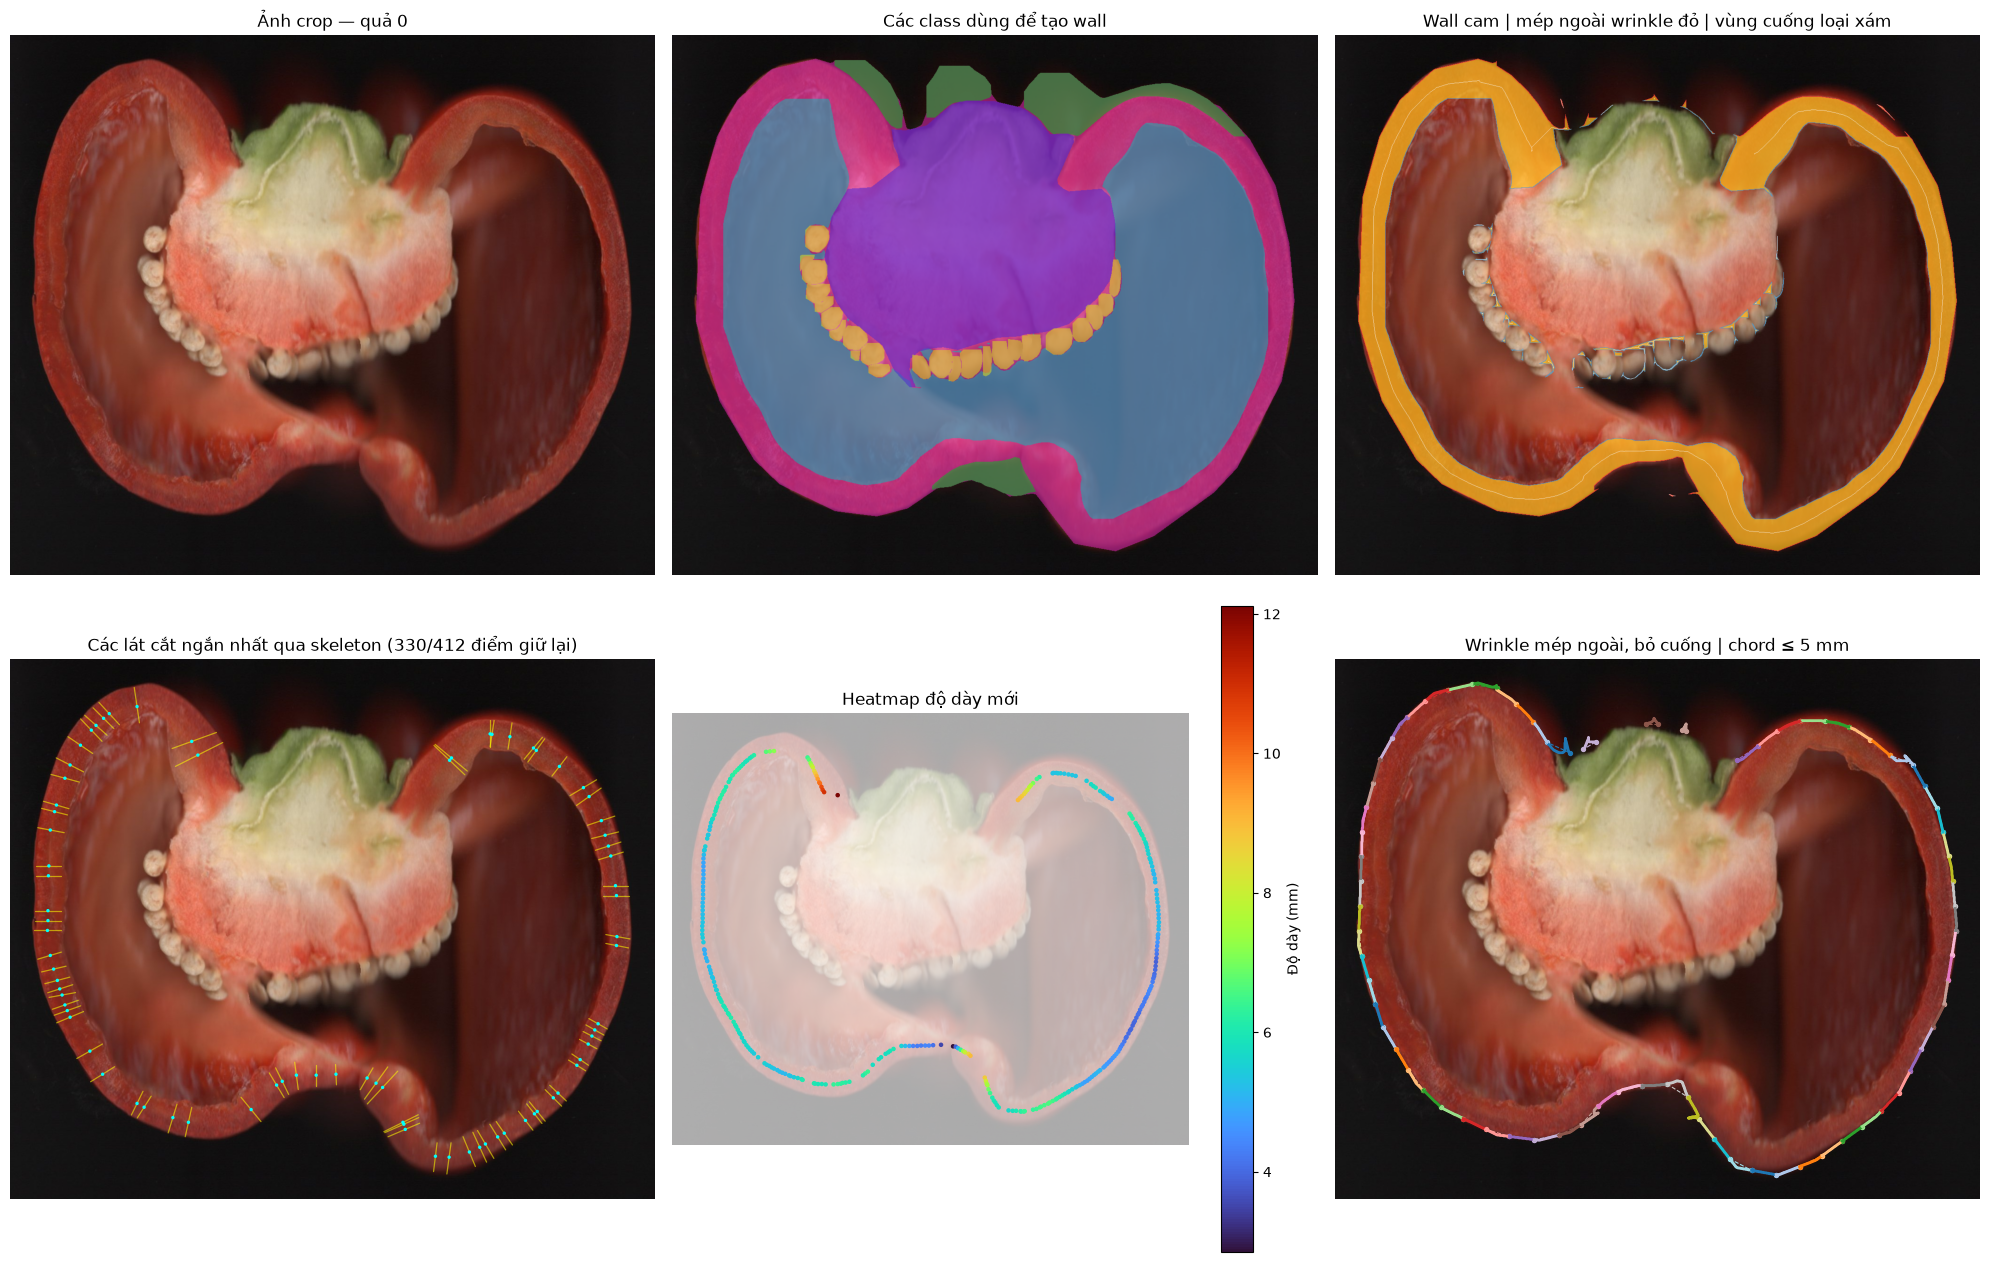

,value
scale_ratio_mm_per_px,0.094787
baseline_avg_mm,4.566190
baseline_max_mm,11.093723
new_mean_mm,5.838924
new_median_mm,5.642084
new_min_mm,0.132506
new_max_mm,12.874114
new_std_mm,1.791516
valid_points,412.000000
sample_spacing_mm,1.000000


,run_id,segment_id,start_x,start_y,end_x,end_y,arc_mm,chord_mm,curvature_ratio,curvature_excess
0,0,0,498.000000,198.000000,450.038861,176.038861,10.429223,5.0,2.085845,1.085845
1,0,1,450.038861,176.038861,420.401704,132.401704,5.299836,5.0,1.059967,0.059967
2,0,2,420.401704,132.401704,384.115229,94.115229,5.109252,5.0,1.021850,0.021850
3,0,3,384.115229,94.115229,343.000000,61.068285,5.357448,5.0,1.071490,0.071490
4,0,4,343.000000,61.068285,290.870687,53.000000,6.144551,5.0,1.228910,0.228910
5,0,5,290.870687,53.000000,239.503747,65.000000,5.340048,5.0,1.068010,0.068010
6,0,6,239.503747,65.000000,192.021591,87.978409,5.402855,5.0,1.080571,0.080571
7,0,7,192.021591,87.978409,152.775366,123.224634,5.103857,5.0,1.020771,0.020771
8,0,8,152.775366,123.224634,121.961221,166.038779,5.323561,5.0,1.064712,0.064712
9,0,9,121.961221,166.038779,96.026819,211.973181,5.372207,5.0,1.074441,0.074441


Real-image checks: PASS


In [21]:
def mask_overlay(image, masks_and_colors, alpha=0.55):
    output = image.astype(float).copy()
    for mask, color in masks_and_colors:
        selector = np.asarray(mask, dtype=bool)
        output[selector] = output[selector] * (1 - alpha) + np.asarray(color) * alpha
    return np.clip(output, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(20, 13))

axes[0, 0].imshow(chili.img)
axes[0, 0].set_title("Ảnh crop — quả 0")

classes_view = mask_overlay(chili.img, [
    (chili.mask_chili, (220, 40, 180)),
    (chili.mask_endocarp, (20, 180, 180)),
    (chili.mask_outer, (20, 180, 40)),
    (chili.mask_placenta, (80, 40, 210)),
    (chili.mask_seed, (220, 220, 30)),
])
axes[0, 1].imshow(classes_view)
axes[0, 1].set_title("Các class dùng để tạo wall")

edge_view = mask_overlay(chili.img, [
    (wall_data["wall"], (255, 190, 30)),
    (wall_data["inner_edge"], (30, 144, 255)),
    (wall_data["wrinkle_outer_edge"], (255, 30, 60)),
    (wall_data["stem_edge_excluded"], (120, 120, 120)),
    (wall_data["skeleton"], (255, 255, 255)),
], alpha=0.7)
axes[0, 2].imshow(edge_view)
axes[0, 2].set_title("Wall cam | mép ngoài wrinkle đỏ | vùng cuống loại xám")

def skeleton_branch_distance(skeleton):
    """Khoảng cách (px) tới điểm nhánh (branch point) gần nhất của skeleton.
    Branch point = pixel skeleton có >= 3 hàng xóm skeleton trong lưới 3x3
    (nơi 2+ nhánh gặp nhau) — đây là vị trí ray-casting hay chọn nhầm hướng
    "mỏng nhất" giữa 2 nhánh gần như vuông góc nhau.
    """
    skeleton = np.asarray(skeleton, dtype=bool)
    kernel = np.ones((3, 3), dtype=int)
    neighbor_count = ndi.convolve(
        skeleton.astype(int), kernel, mode="constant", cval=0
    ) - skeleton.astype(int)
    branch_points = skeleton & (neighbor_count >= 3)
    if not np.any(branch_points):
        return np.full(skeleton.shape, np.inf)
    return ndi.distance_transform_edt(~branch_points)

def filter_clean_thickness_points(
    points,
    wall_data,
    ratio,
    k=8,
    thickness_mad_multiplier=3.0,
    angle_mad_multiplier=2.0,
    stem_margin_mm=1.5,
    branch_margin_mm=1.5,
):
    """Loại điểm đo nhiễu: quá gần cuống, quá gần điểm phân nhánh skeleton,
    hoặc lệch bất thường (thickness/góc) so với các hàng xóm gần nhất.
    stem_margin_mm/branch_margin_mm quy đổi theo ratio để không bị "ăn"
    quá đà trên quả nhỏ/mảnh — dùng mm thay vì px cố định để ổn định
    qua nhiều ảnh có ratio khác nhau."""
    stem_margin_px = stem_margin_mm / ratio
    branch_margin_px = branch_margin_mm / ratio

    stem_distance = ndi.distance_transform_edt(~wall_data["stem_exclusion"])
    near_stem = bilinear_many(
        stem_distance, points.skeleton_x.to_numpy(), points.skeleton_y.to_numpy()
    ) < stem_margin_px

    branch_distance = skeleton_branch_distance(wall_data["skeleton"])
    near_branch = bilinear_many(
        branch_distance, points.skeleton_x.to_numpy(), points.skeleton_y.to_numpy(), np.inf
    ) < branch_margin_px

    xy = points[["skeleton_x", "skeleton_y"]].to_numpy()
    tree = cKDTree(xy)
    neighbor_k = min(k + 1, len(xy))
    _, neighbor_idx = tree.query(xy, k=neighbor_k)
    neighbor_idx = np.atleast_2d(neighbor_idx)[:, 1:]  # bỏ chính điểm đó (cột 0)

    thickness = points.thickness_mm.to_numpy()
    local_median = np.median(thickness[neighbor_idx], axis=1)
    local_mad = np.maximum(np.median(np.abs(thickness[neighbor_idx] - local_median[:, None]), axis=1), 1e-6)
    thickness_deviation = np.abs(thickness - local_median) / local_mad
    is_thickness_outlier = thickness_deviation > thickness_mad_multiplier

    angles = points.angle_deg.to_numpy()
    neighbor_angles = angles[neighbor_idx]
    diff = np.abs(neighbor_angles - angles[:, None])
    circ_diff = np.minimum(diff, 180.0 - diff)  # khoảng cách vòng tròn từng cặp hàng xóm
    angle_local_median = np.median(circ_diff, axis=1)
    angle_local_mad = np.maximum(
        np.median(np.abs(circ_diff - angle_local_median[:, None]), axis=1), 1e-6
    )
    is_angle_outlier = angle_local_median > angle_mad_multiplier * np.median(angle_local_median)

    clean = points[
        (~near_stem) & (~near_branch) & (~is_thickness_outlier) & (~is_angle_outlier)
    ].reset_index(drop=True)
    return clean

thickness_points_clean = filter_clean_thickness_points(
    thickness_points, wall_data, ratio, stem_margin_mm=1.5, branch_margin_mm=2.5
)

axes[1, 0].imshow(chili.img)
sample_count = min(80, len(thickness_points_clean))
sample_indices = np.linspace(0, len(thickness_points_clean) - 1, sample_count, dtype=int)
sampled = thickness_points_clean.iloc[sample_indices]
for _, row in sampled.iterrows():
    axes[1, 0].plot(
        [row.outer_x, row.inner_x],
        [row.outer_y, row.inner_y],
        color="yellow",
        linewidth=0.9,
        alpha=0.55,
        solid_capstyle="round",
        zorder=2,
    )
axes[1, 0].scatter(
    sampled.skeleton_x,
    sampled.skeleton_y,
    s=6,
    c="cyan",
    edgecolors="none",
    zorder=3,
)
axes[1, 0].set_title(
    f"Các lát cắt ngắn nhất qua skeleton ({len(thickness_points_clean)}/{len(thickness_points)} điểm giữ lại)"
)

axes[1, 1].imshow(chili.img, alpha=0.35)
scatter = axes[1, 1].scatter(
    thickness_points_clean.skeleton_x,
    thickness_points_clean.skeleton_y,
    c=thickness_points_clean.thickness_mm,
    s=5,
    cmap="turbo",
)
fig.colorbar(scatter, ax=axes[1, 1], label="Độ dày (mm)")
axes[1, 1].set_title("Heatmap độ dày mới")

axes[1, 2].imshow(chili.img)
colors = plt.cm.tab20(np.linspace(0, 1, 20))
global_segment_index = 0
for points, cumulative, segments in wrinkle_geometries:
    for segment in segments:
        section = slice_polyline(
            points, cumulative, segment["start_s"], segment["end_s"]
        )
        color = colors[global_segment_index % len(colors)]
        axes[1, 2].plot(section[:, 0], section[:, 1], color=color, linewidth=2.0)
        axes[1, 2].plot(
            [segment["start"][0], segment["end"][0]],
            [segment["start"][1], segment["end"][1]],
            color=color,
            linewidth=0.8,
            linestyle="--",
        )
        axes[1, 2].scatter(
            [segment["start"][0], segment["end"][0]],
            [segment["start"][1], segment["end"][1]],
            color=[color],
            s=8,
        )
        global_segment_index += 1
axes[1, 2].set_title(f"Wrinkle mép ngoài, bỏ cuống | chord ≤ {WRINKLE_SEGMENT_THRESHOLD_MM:g} mm")

for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([
    {
        "scale_ratio_mm_per_px": ratio,
        **thickness_summary,
        **wrinkle_summary,
    }
])
display(comparison.T.rename(columns={0: "value"}))
display(wrinkle_segments.head(20))

assert thickness_coverage > 0
assert np.isfinite(comparison.select_dtypes(include=[np.number]).to_numpy()).all()
print("Real-image checks: PASS")